In [556]:
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.datasets import make_circles

In [557]:
device="cuda" if torch.cuda.is_available() else "cpu"

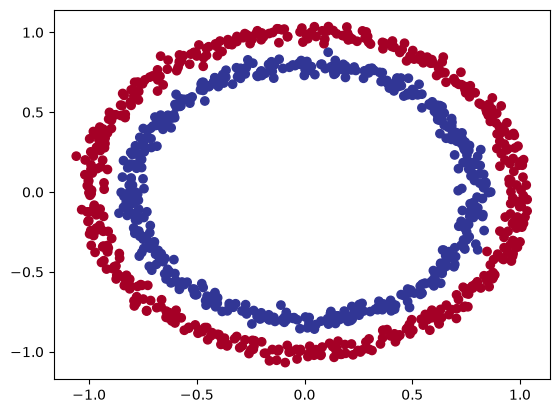

In [558]:
n_sample=1000

X,y=make_circles(n_samples=1000,noise=0.03,random_state=42)

plt.scatter(X[:,0],X[:,1],c=y,cmap=plt.cm.RdYlBu)

In [559]:
from sklearn.model_selection import train_test_split

X=torch.from_numpy(X).type(torch.float)
y=torch.from_numpy(y).type(torch.float)

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [560]:
X_train[:5],y_train[:5]

(tensor([[ 0.6579, -0.4651],
         [ 0.6319, -0.7347],
         [-1.0086, -0.1240],
         [-0.9666, -0.2256],
         [-0.1666,  0.7994]]),
 tensor([1., 0., 0., 0., 1.]))

In [561]:
class CircleModel_1(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_1=nn.Linear(in_features=2,out_features=10)
        self.layer_2=nn.Linear(in_features=10,out_features=10)
        self.layer_3=nn.Linear(in_features=10,out_features=1)
        self.relu=nn.ReLU()
    def forward(self,X):
        return self.layer_3(self.relu(self.layer_2(self.relu(self.layer_1(X)))))

model_3=CircleModel_1().to(device)
model_3

CircleModel_1(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=10, bias=True)
  (layer_3): Linear(in_features=10, out_features=1, bias=True)
  (relu): ReLU()
)

In [562]:
def accuracy_fn(y_true,y_pred):
    correct=torch.eq(y_true,y_pred).sum().item()
    acc=(correct/len(y_pred))*100
    return acc

In [563]:
loss_fn=nn.BCEWithLogitsLoss()
optimizer=torch.optim.SGD(params=model_3.parameters(),lr=0.1)

In [564]:
from sklearn.model_selection import train_test_split
torch.manual_seed(42)
torch.cuda.manual_seed(42)


X_train=X_train.to(device)
X_test=X_test.to(device)
y_train=y_train.to(device)
y_test=y_test.to(device)

epocs=1000

for epoc in range(epocs):

    model_3.train()

    y_logits=model_3(X_train).squeeze()
    y_pred=torch.round(torch.sigmoid(y_logits))

    loss=loss_fn(y_logits,y_train)

    acc=accuracy_fn(y_train,y_pred)

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    model_3.eval()

    with torch.inference_mode():
        test_logits=model_3(X_test).squeeze()
        test_pred=torch.round(torch.sigmoid(test_logits))
        test_loss=loss_fn(test_logits,y_test)

        test_acc=accuracy_fn(y_test,test_pred)

    if epoc%100==0:
        print(f"Epoc: {epoc} | Loss: {loss:.5f}, Acc: {acc} | Test Loss: {test_loss} | Test Acc: {test_acc:.5f}")

Epoc: 0 | Loss: 0.69295, Acc: 50.0 | Test Loss: 0.6931881308555603 | Test Acc: 50.00000
Epoc: 100 | Loss: 0.69115, Acc: 52.87500000000001 | Test Loss: 0.6910240054130554 | Test Acc: 52.50000
Epoc: 200 | Loss: 0.68977, Acc: 53.37499999999999 | Test Loss: 0.6893961429595947 | Test Acc: 55.00000
Epoc: 300 | Loss: 0.68795, Acc: 53.0 | Test Loss: 0.6872316002845764 | Test Acc: 56.00000
Epoc: 400 | Loss: 0.68517, Acc: 52.75 | Test Loss: 0.6841148734092712 | Test Acc: 56.50000
Epoc: 500 | Loss: 0.68102, Acc: 52.75 | Test Loss: 0.6794120669364929 | Test Acc: 56.50000
Epoc: 600 | Loss: 0.67515, Acc: 54.50000000000001 | Test Loss: 0.6728507876396179 | Test Acc: 56.00000
Epoc: 700 | Loss: 0.66659, Acc: 58.375 | Test Loss: 0.6632164716720581 | Test Acc: 59.00000
Epoc: 800 | Loss: 0.65160, Acc: 64.0 | Test Loss: 0.647568941116333 | Test Acc: 67.50000
Epoc: 900 | Loss: 0.62362, Acc: 74.0 | Test Loss: 0.6214525699615479 | Test Acc: 79.00000


In [565]:
model_3.eval()
with torch.inference_mode():
    y_preds=torch.round(torch.sigmoid(model_3(X_test))).squeeze()

y_preds[:5],y_test[:5]

(tensor([1., 0., 1., 0., 0.], device='cuda:0'),
 tensor([1., 0., 1., 0., 1.], device='cuda:0'))

In [566]:
import requests
from pathlib import Path
if Path("helper_functions.py").is_file():
    print("helper_functions already exsists")
else:
    print("Download helper_functions.py")
    request=requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
    with open("helper_functions.py", "wb") as f:
        f.write(request.content)
from helper_functions import plot_predictions,plot_decision_boundary

helper_functions already exsists


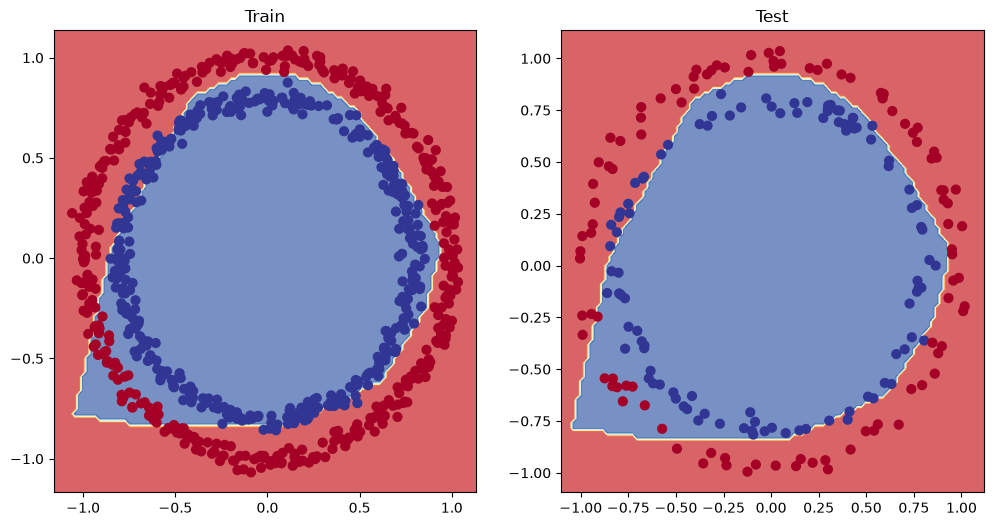

In [567]:
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.title("Train")
plot_decision_boundary(model_3,X_train,y_train)
plt.subplot(1,2,2)
plt.title("Test")
plot_decision_boundary(model_3,X_test,y_test)


In [568]:
A=torch.arange(-10,10,1,dtype=torch.float32)
A.dtype

torch.float32

In [569]:
A

tensor([-10.,  -9.,  -8.,  -7.,  -6.,  -5.,  -4.,  -3.,  -2.,  -1.,   0.,   1.,
          2.,   3.,   4.,   5.,   6.,   7.,   8.,   9.])

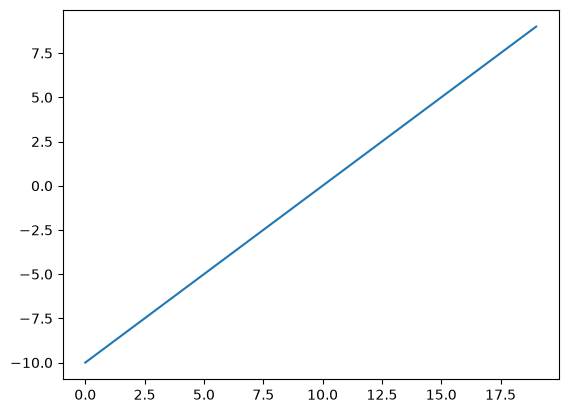

In [570]:
plt.plot(A);

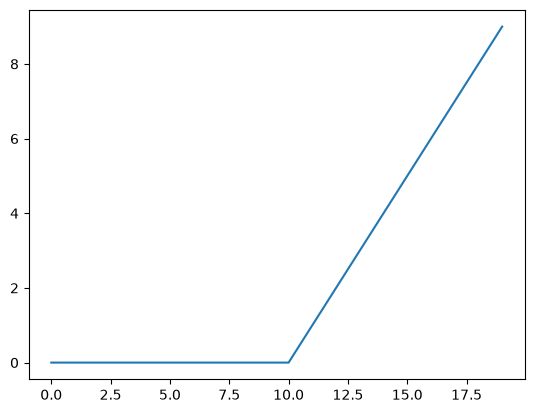

In [571]:
plt.plot(torch.relu(A));

In [572]:
def relu(X: torch.Tensor) -> torch.Tensor:
    return torch.maximum(torch.tensor(0),X)
relu(A)

tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 2., 3., 4., 5., 6., 7.,
        8., 9.])

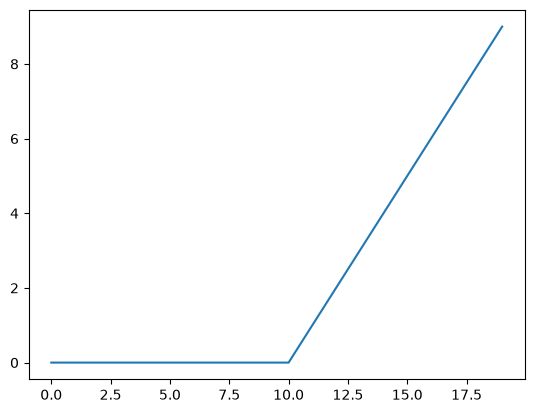

In [573]:
plt.plot(relu(A))

In [574]:
def sigmoid(X: torch.Tensor) -> torch.Tensor:
    return (1/(1+torch.exp(-X)))

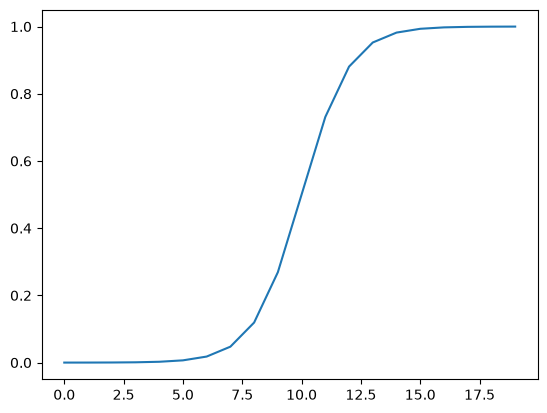

In [575]:
plt.plot(sigmoid(A))

Multi classclassification


In [576]:
import torch
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [577]:
NUM_CLASSES = 4
NUM_FEATURES = 2
RANDOM_SEED = 42

X_blob, y_blob = make_blobs(
    n_samples=1000,
    n_features=NUM_FEATURES,
    centers=NUM_CLASSES,
    cluster_std=1.5,
    random_state=RANDOM_SEED
)

X_blob=torch.from_numpy(X_blob).type(torch.float)
y_blob=torch.from_numpy(y_blob).type(torch.LongTensor)

X_blob_train,X_blob_test,y_blob_train,y_blob_test=train_test_split(X_blob,y_blob,test_size=0.2,random_state=42)

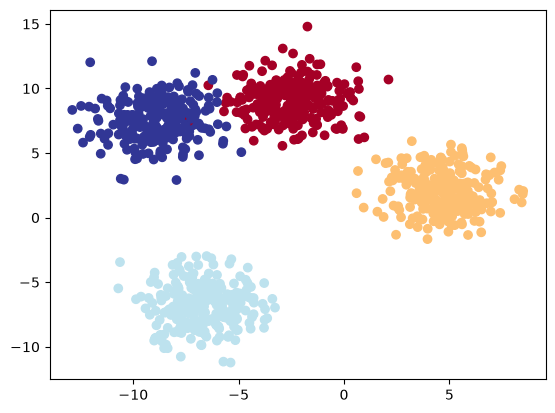

In [578]:
plt.scatter(X_blob[:,0],X_blob[:,1],c=y_blob,cmap=plt.cm.RdYlBu)

In [579]:
device="cuda" if torch.cuda.is_available() else "cpu"

In [580]:
class BlobModel(nn.Module):
    def __init__(self,input_features,output_features,hidden_units=8):
        super().__init__()
        self.linear_layer_stack=nn.Sequential(
            nn.Linear(in_features=input_features,out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units,out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units,out_features=output_features))

    def forward(self,X):
        return self.linear_layer_stack(X)

model_4=BlobModel(input_features=2,output_features=4,hidden_units=8).to(device)
model_4

BlobModel(
  (linear_layer_stack): Sequential(
    (0): Linear(in_features=2, out_features=8, bias=True)
    (1): ReLU()
    (2): Linear(in_features=8, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=4, bias=True)
  )
)

In [581]:
X_blob_train.shape,y_blob_train.shape

(torch.Size([800, 2]), torch.Size([800]))

In [582]:
torch.unique(y_blob_train)

tensor([0, 1, 2, 3])

In [583]:
loss_fn=nn.CrossEntropyLoss()
optimizer=torch.optim.SGD(params=model_4.parameters(),lr=0.1)

In [584]:
X_blob_train=X_blob_train.to(device)
X_blob_test=X_blob_test.to(device)
y_blob_train=y_blob_train.to(device)
y_blob_test=y_blob_test.to(device)


next(model_4.parameters()).device

device(type='cuda', index=0)

In [585]:
X_blob_test.device

device(type='cuda', index=0)

In [586]:
model_4.eval()
with torch.inference_mode():
    y_logits=model_4(X_blob_test)
y_logits[:10]

tensor([[-0.7646, -0.7412, -1.5777, -1.1376],
        [-0.0973, -0.9431, -0.5963, -0.1371],
        [ 0.2528, -0.2379,  0.1882, -0.0066],
        [-0.4134, -0.5204, -0.9303, -0.6963],
        [-0.3118, -1.3736, -1.1991, -0.3834],
        [-0.1497, -1.0617, -0.7107, -0.1645],
        [ 0.1539, -0.2887,  0.1520, -0.0109],
        [-0.2154, -1.1795, -0.9300, -0.2745],
        [ 0.2443, -0.2472,  0.1649,  0.0061],
        [-0.2329, -1.2120, -0.9849, -0.3004]], device='cuda:0')

In [587]:
y_blob_test[:10]

tensor([1, 3, 2, 1, 0, 3, 2, 0, 2, 0], device='cuda:0')

In [588]:
y_pred_probs=torch.softmax(y_logits,dim=1)
print(y_logits[:5])
print(y_pred_probs[:5])

tensor([[-0.7646, -0.7412, -1.5777, -1.1376],
        [-0.0973, -0.9431, -0.5963, -0.1371],
        [ 0.2528, -0.2379,  0.1882, -0.0066],
        [-0.4134, -0.5204, -0.9303, -0.6963],
        [-0.3118, -1.3736, -1.1991, -0.3834]], device='cuda:0')
tensor([[0.3169, 0.3244, 0.1405, 0.2182],
        [0.3336, 0.1432, 0.2026, 0.3206],
        [0.3011, 0.1843, 0.2823, 0.2323],
        [0.3078, 0.2766, 0.1836, 0.2320],
        [0.3719, 0.1286, 0.1532, 0.3463]], device='cuda:0')


In [589]:
torch.max(y_pred_probs[0])

tensor(0.3244, device='cuda:0')

In [590]:
y_preds=torch.argmax(y_pred_probs,dim=1)
y_preds

tensor([1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 3, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
        1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3, 0, 0, 1, 0, 1, 0, 0, 0,
        0, 0, 0, 0, 3, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
        1, 0, 0, 0, 0, 1, 0, 1], device='cuda:0')

In [591]:
y_blob_test

tensor([1, 3, 2, 1, 0, 3, 2, 0, 2, 0, 0, 1, 0, 0, 0, 3, 3, 2, 3, 3, 3, 0, 1, 2,
        2, 2, 3, 0, 1, 0, 3, 1, 1, 3, 1, 2, 1, 3, 0, 2, 0, 3, 3, 2, 0, 3, 1, 1,
        0, 3, 1, 0, 1, 1, 3, 2, 1, 1, 3, 2, 2, 0, 3, 2, 2, 0, 0, 3, 3, 0, 0, 3,
        3, 3, 2, 3, 3, 3, 3, 1, 0, 2, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 1, 3, 3, 3,
        1, 0, 3, 2, 0, 0, 3, 0, 2, 3, 1, 0, 3, 2, 1, 1, 0, 2, 2, 3, 0, 0, 1, 2,
        2, 3, 0, 1, 2, 0, 0, 0, 2, 3, 1, 2, 3, 2, 0, 3, 0, 0, 1, 1, 1, 0, 2, 2,
        2, 2, 0, 3, 3, 2, 2, 1, 3, 2, 0, 0, 3, 3, 2, 1, 2, 0, 3, 2, 0, 3, 2, 0,
        2, 2, 2, 0, 3, 1, 1, 1, 1, 1, 3, 1, 0, 2, 2, 1, 2, 2, 0, 1, 2, 2, 0, 0,
        1, 3, 2, 0, 3, 1, 2, 1], device='cuda:0')

In [592]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

epocs=100

for epoc in range(epocs):

    model_4.train()

    y_logits=model_4(X_blob_train)
    y_pred=torch.softmax(y_logits,dim=1).argmax(dim=1)

    loss=loss_fn(y_logits,y_blob_train)

    acc=accuracy_fn(y_blob_train,y_pred)

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    model_4.eval()
    with torch.inference_mode():
        test_logits=model_4(X_blob_test)
        test_preds=torch.softmax(test_logits,dim=1).argmax(dim=1)

        test_loss=loss_fn(test_logits,test_preds)

        test_acc=accuracy_fn(y_blob_test,test_preds)

    if epoc%10==0:
        print(f"Epoc: {epoc} | Loss: {loss:.4f}, Acc: {acc:.2f} | Test Loss: {test_loss:.4f} | Test Acc: {test_acc:.2f}%")



Epoc: 0 | Loss: 1.1588, Acc: 40.38 | Test Loss: 1.0494 | Test Acc: 48.00%
Epoc: 10 | Loss: 0.6448, Acc: 96.75 | Test Loss: 0.6578 | Test Acc: 97.50%
Epoc: 20 | Loss: 0.4254, Acc: 98.50 | Test Loss: 0.4307 | Test Acc: 100.00%
Epoc: 30 | Loss: 0.2529, Acc: 99.12 | Test Loss: 0.2448 | Test Acc: 99.50%
Epoc: 40 | Loss: 0.1123, Acc: 99.25 | Test Loss: 0.1015 | Test Acc: 99.50%
Epoc: 50 | Loss: 0.0663, Acc: 99.25 | Test Loss: 0.0574 | Test Acc: 99.50%
Epoc: 60 | Loss: 0.0507, Acc: 99.25 | Test Loss: 0.0416 | Test Acc: 99.50%
Epoc: 70 | Loss: 0.0430, Acc: 99.25 | Test Loss: 0.0334 | Test Acc: 99.50%
Epoc: 80 | Loss: 0.0384, Acc: 99.25 | Test Loss: 0.0281 | Test Acc: 99.50%
Epoc: 90 | Loss: 0.0352, Acc: 99.25 | Test Loss: 0.0242 | Test Acc: 99.50%


In [593]:
model_4.eval()
with torch.inference_mode():
    y_logits=model_4(X_blob_test)

y_logits[:10]

tensor([[-0.6249,  5.9860, -7.6323, -8.4470],
        [-2.1738, -6.3750, -3.7202,  3.1203],
        [-3.4102, -3.8958,  3.1567, -2.6119],
        [-1.1505,  4.1962, -3.8472, -4.8820],
        [ 3.7548, -1.3391, -9.1422, -6.9466],
        [-2.8211, -7.5767, -4.2944,  3.7944],
        [-3.0306, -3.3328,  2.7955, -2.1374],
        [ 3.3761, -4.0375, -6.8987, -3.5503],
        [-4.3620, -4.9904,  3.8123, -3.3814],
        [ 3.5012, -3.0281, -7.5401, -4.7064]], device='cuda:0')

In [594]:
y_pred_probs=torch.softmax(y_logits,dim=1)
y_pred_probs[:10]

tensor([[1.3438e-03, 9.9865e-01, 1.2164e-06, 5.3854e-07],
        [4.9905e-03, 7.4740e-05, 1.0630e-03, 9.9387e-01],
        [1.3985e-03, 8.6060e-04, 9.9463e-01, 3.1073e-03],
        [4.7389e-03, 9.9483e-01, 3.1956e-04, 1.1353e-04],
        [9.9388e-01, 6.0966e-03, 2.4904e-06, 2.2378e-05],
        [1.3372e-03, 1.1504e-05, 3.0644e-04, 9.9834e-01],
        [2.9138e-03, 2.1537e-03, 9.8781e-01, 7.1181e-03],
        [9.9838e-01, 6.0198e-04, 3.4435e-05, 9.7989e-04],
        [2.8147e-04, 1.5016e-04, 9.9882e-01, 7.5044e-04],
        [9.9825e-01, 1.4575e-03, 1.5998e-05, 2.7210e-04]], device='cuda:0')

In [595]:
y_blob_test

tensor([1, 3, 2, 1, 0, 3, 2, 0, 2, 0, 0, 1, 0, 0, 0, 3, 3, 2, 3, 3, 3, 0, 1, 2,
        2, 2, 3, 0, 1, 0, 3, 1, 1, 3, 1, 2, 1, 3, 0, 2, 0, 3, 3, 2, 0, 3, 1, 1,
        0, 3, 1, 0, 1, 1, 3, 2, 1, 1, 3, 2, 2, 0, 3, 2, 2, 0, 0, 3, 3, 0, 0, 3,
        3, 3, 2, 3, 3, 3, 3, 1, 0, 2, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 1, 3, 3, 3,
        1, 0, 3, 2, 0, 0, 3, 0, 2, 3, 1, 0, 3, 2, 1, 1, 0, 2, 2, 3, 0, 0, 1, 2,
        2, 3, 0, 1, 2, 0, 0, 0, 2, 3, 1, 2, 3, 2, 0, 3, 0, 0, 1, 1, 1, 0, 2, 2,
        2, 2, 0, 3, 3, 2, 2, 1, 3, 2, 0, 0, 3, 3, 2, 1, 2, 0, 3, 2, 0, 3, 2, 0,
        2, 2, 2, 0, 3, 1, 1, 1, 1, 1, 3, 1, 0, 2, 2, 1, 2, 2, 0, 1, 2, 2, 0, 0,
        1, 3, 2, 0, 3, 1, 2, 1], device='cuda:0')

In [596]:
y_preds=torch.argmax(y_pred_probs,dim=1)
y_preds[:10]

tensor([1, 3, 2, 1, 0, 3, 2, 0, 2, 0], device='cuda:0')

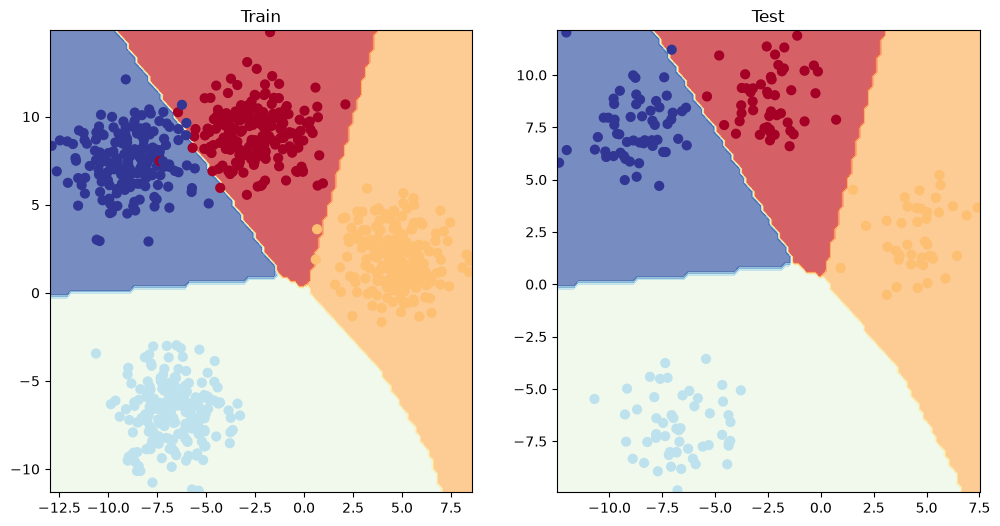

In [597]:
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.title("Train")
plot_decision_boundary(model_4,X_blob_train,y_blob_train)
plt.subplot(1,2,2)
plt.title("Test")
plot_decision_boundary(model_4,X_blob_test,y_blob_test)


In [598]:
from torchmetrics import Accuracy

In [600]:
torchmetric_accuracy=Accuracy(task="multiclass",num_classes=4).to(device)

torchmetric_accuracy(y_preds,y_blob_test)

tensor(0.9950, device='cuda:0')